# Walkthrough: from log lines to an alert

This notebook runs the whole pipeline on synthetic logs and looks at each step. Install first with
`pip install -e ".[notebook]"` (adds matplotlib).

In [1]:
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from loganomaly.evaluate import label_windows, load_attacks, load_events, roc_auc
from loganomaly.pipeline import TrainConfig, analyse, train
from loganomaly.report import findings
from loganomaly.synth import DatasetSpec, generate, write

spec = DatasetSpec(days=14, train_days=7, seed=1)
root = Path(tempfile.mkdtemp())
write(generate(spec), spec, root)
events, manifest = load_events(root)
print(f"{len(events):,} events over {spec.days} days")

101,723 events over 14 days


## 1. What normal looks like

Events per hour, by log family. Daily rhythm, quiet weekends.

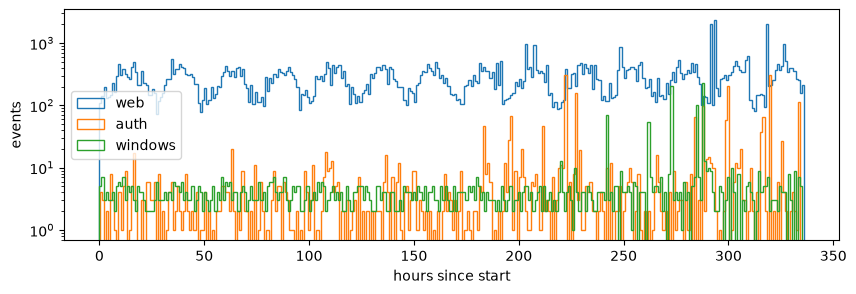

In [2]:
start = manifest["start"]
hours = np.array([(e.ts - start) / 3600 for e in events])
fig, ax = plt.subplots(figsize=(10, 3))
for source in ("web", "auth", "windows"):
    h = np.array([(e.ts - start) / 3600 for e in events if e.source == source])
    ax.hist(h, bins=spec.days * 24, histtype="step", label=source)
ax.set_xlabel("hours since start")
ax.set_ylabel("events")
ax.set_yscale("log")
ax.legend()
plt.show()

## 2. Train on the first week, score the second

In [3]:
cut = manifest["train_end"]
bundle = train([e for e in events if e.ts < cut], TrainConfig(seed=1))
analysis = analyse(bundle, [e for e in events if e.ts >= cut])
print({k: round(v, 4) for k, v in bundle.thresholds.items()})
print(f"{len(analysis.windows):,} windows scored, trained in {bundle.info['total_seconds']} s")

{'zscore': 2.6488, 'iforest': 0.6605, 'autoencoder': 0.2013, 'sequence': 6.3362}
7,953 windows scored, trained in 3.741 s


## 3. Scores against labels

The synthetic generator knows which windows are attacks, so we can check the scores.

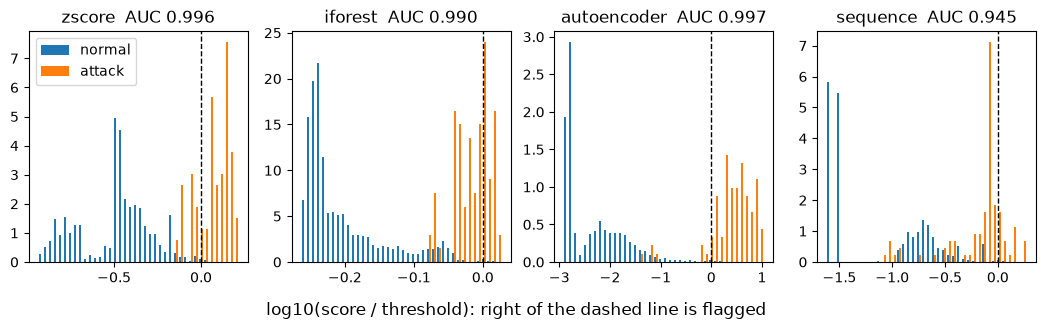

In [4]:
attacks = [a for a in load_attacks(root) if a.split == "test"]
y, hard, _ = label_windows(analysis.windows, attacks, bundle.window)
use = ~hard
fig, axes = plt.subplots(1, 4, figsize=(13, 3), sharey=False)
for ax, name in zip(axes, ("zscore", "iforest", "autoencoder", "sequence"), strict=True):
    s = np.log10(analysis.ratios[name][use] + 1e-3)
    ax.hist([s[~y[use]], s[y[use]]], bins=40, label=["normal", "attack"], density=True)
    ax.axvline(0, color="k", ls="--", lw=1)
    ax.set_title(f"{name}  AUC {roc_auc(y[use], analysis.scores[name][use]):.3f}")
axes[0].legend()
fig.supxlabel("log10(score / threshold): right of the dashed line is flagged", y=-0.08)
plt.show()

## 4. The reasons

The top alerts of the vote, each with the features that were out of range.

In [5]:
for item in findings(bundle, analysis, "vote", 6):
    print(f"{item.severity():6s} x{item.ratio:.1f}  {item.entity}  ({item.events} events)")
    for reason in item.reasons[:3]:
        print("        -", reason)

high   x3.1  ip:193.229.80.87  (1 events)
        - win_logon_failed events: 1 (normally at most 0)
        - novel user: 1 (normally at most 0)
medium x2.5  user:luca@WIN-DESK01  (4 events)
        - win_scheduled_task_created events: 1 (normally at most 0)
        - win_service_installed events: 1 (normally at most 0)
        - win_group_member_added events: 1 (normally at most 0)
medium x2.5  user:luca@WIN-DESK01  (4 events)
        - win_scheduled_task_created events: 1 (normally at most 0)
        - win_service_installed events: 1 (normally at most 0)
        - win_group_member_added events: 1 (normally at most 0)
medium x2.3  user:luca@WIN-DESK01  (1 events)
        - win_privileged_logon events: 1 (normally at most 0)
medium x2.3  user:luca@WIN-DESK01  (1 events)
        - win_privileged_logon events: 1 (normally at most 0)
medium x2.2  user:luca@WIN-DESK01  (1 events)
        - win_privileged_logon events: 1 (normally at most 0)


## 5. Reading it

- The autoencoder and the z-score separate attacks from normal windows best; the Isolation Forest's
  attack scores bunch up right at its threshold, because most columns are zero almost everywhere
  and random cuts rarely separate anything.
- The next-event network has the weakest separation here: it sees order, not volume.
- See `docs/results.md` for the numbers averaged over five datasets.